# Do device types group by technology or by medical field?

**Question.** When medical device types are linked by how similar their adverse event reports read, do they group by the medical field they are used in, or by the technology they are built on?

**Hypothesis (H).** Device types group by technology more than by medical field. Example: a spinal cord stimulator's reports should read more like a pacemaker's (another implanted pulse generator, different field) than like a spinal implant's (same field, different technology).

**Network.**
- **Nodes** are product codes, the FDA's kinds of device. Each report's own product code is used.
- **Text** is the `event_description` of each report, embedded with `all-MiniLM-L6-v2`.
- Each code is represented by the average of its report embeddings.
- **Edges:** every code is linked to its 5 most similar codes by cosine similarity.

**The two labels.** Neither one is used to build the network. They are only compared with it afterwards.

| label | source | values |
|---|---|---|
| medical field | FDA `advisory_committee` column | 16 fields, such as Cardiovascular or Neurology |
| technology | `labels/technology_labels.csv`, set by hand from each code's FDA name | 19 types, such as implanted pulse generator, stent, lens or lab test |

Technology describes what the device physically is and does, ignoring the body part. A pacemaker and a deep brain stimulator are both `implanted_pulse_generator`. The labels were drafted from device names only, never from the network, and should be reviewed by the group.

**Decision rules, fixed before looking at results:**

| | rule |
|---|---|
| technology beyond field | technology still groups links after its labels are shuffled **within** each field, so field alone cannot explain it (p < 0.01) |
| field beyond technology | the same test the other way round |
| **H supported** | technology assortativity is higher than field assortativity, technology matters beyond field, and both hold in the problem-term network and for 3, 5 and 10 neighbours |
| **H rejected** | field assortativity is at least as high as technology's, **and** technology does not matter beyond field |
| in between | partly supported |

**Check.** A second network is built from the FDA problem terms on the same reports (`product_problems` and `patient_problems`), with no embeddings. If both networks give the same answer, it does not depend on the embedding model.

Run `data_import.ipynb` first. The sample and the embeddings are cached in `data/processed/`, so only the first run is slow (about 20 minutes on a laptop CPU).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import normalized_mutual_info_score

PROCESSED_DIR = Path("data/processed")
SAMPLE_PATH = PROCESSED_DIR / "embedding_sample.csv.gz"
EMBEDDINGS_PATH = PROCESSED_DIR / "embedding_sample_minilm.npy"
TECHNOLOGY_PATH = Path("labels/technology_labels.csv")

SEED = 42
MIN_REPORTS = 30       # a code needs this many usable descriptions to be a node
MAX_REPORTS = 300      # at most this many descriptions per code are embedded
MIN_CHARS, MAX_CHARS = 40, 5_000
K = 5                  # neighbours per code in the network
N_SHUFFLES = 1_000
LABELS = ["field", "technology"]

COMMITTEES = {
    "AN": "Anesthesiology", "CH": "Clinical chemistry", "CV": "Cardiovascular", "DE": "Dental",
    "EN": "Ear, nose, throat", "GU": "Gastro and urology", "HE": "Hematology", "HO": "General hospital",
    "IM": "Immunology", "MG": "Medical genetics", "MI": "Microbiology", "NE": "Neurology",
    "OB": "Obstetrics and gynecology", "OP": "Ophthalmic", "OR": "Orthopedic", "PA": "Pathology",
    "PM": "Physical medicine", "RA": "Radiology", "SU": "General and plastic surgery", "TX": "Clinical toxicology",
}

rng = np.random.default_rng(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. Sample the reports

A report is usable if its text is not a repeat of an earlier report for the same device (`is_repeat_text`), and its description has 40 to 5,000 characters. Repeats are real reports with copied template text: they would pull a code's average towards one template. Shorter texts say little ("see narrative"), and longer ones are often registry extracts rather than one event.

Up to 300 usable reports are drawn at random per product code. More would mostly add insulin pumps and glucose monitors, without changing their average.

In [2]:
devices = pd.read_csv(PROCESSED_DIR / "pma_devices_2020_2025.csv", dtype=str)
reports = pd.read_csv(
    PROCESSED_DIR / "maude_reports.csv" if (PROCESSED_DIR / "maude_reports.csv").exists() else PROCESSED_DIR / "maude_reports.csv.gz",
    usecols=["mdr_report_key", "pma_number", "product_code", "event_type", "is_repeat_text", "text_chars",
             "product_problems", "patient_problems"],
    dtype=str,
)
reports["text_chars"] = reports["text_chars"].astype(int)

usable = reports[(reports["is_repeat_text"] == "False") & reports["text_chars"].between(MIN_CHARS, MAX_CHARS)]
per_code = usable["product_code"].value_counts()
kept_codes = per_code[per_code >= MIN_REPORTS].index

print(f"Usable reports: {len(usable):,} of {len(reports):,}")
print(f"Product codes: {per_code.size}, of which {kept_codes.size} have at least {MIN_REPORTS} usable reports")
print(f"Those codes cover {usable['product_code'].isin(kept_codes).mean():.1%} of usable reports")

Usable reports: 1,875,417 of 2,422,364
Product codes: 402, of which 201 have at least 30 usable reports
Those codes cover 99.9% of usable reports


In [3]:
if SAMPLE_PATH.exists():
    sample = pd.read_csv(SAMPLE_PATH, dtype=str)
else:
    sample = (
        usable[usable["product_code"].isin(kept_codes)]
        .sample(frac=1, random_state=SEED)
        .groupby("product_code").head(MAX_REPORTS)
        .drop(columns=["is_repeat_text"])
    )
    # The text file is 4 GB, so it is read in chunks and only sampled reports are kept.
    text_path = PROCESSED_DIR / "maude_text.csv"
    if not text_path.exists():
        text_path = PROCESSED_DIR / "maude_text.csv.gz"
    wanted = set(sample["mdr_report_key"])
    texts = []
    for chunk in pd.read_csv(text_path, usecols=["mdr_report_key", "event_description"], dtype=str, chunksize=200_000):
        texts.append(chunk[chunk["mdr_report_key"].isin(wanted)])
    texts = pd.concat(texts)
    sample = sample.merge(texts, on="mdr_report_key", how="inner").sort_values(["product_code", "mdr_report_key"])
    sample.to_csv(SAMPLE_PATH, index=False)

sample = sample.reset_index(drop=True)
assert sample["event_description"].notna().all()
assert sample["mdr_report_key"].is_unique
print(f"Sample: {len(sample):,} reports from {sample['product_code'].nunique()} product codes "
      f"({len(sample) / usable['product_code'].isin(kept_codes).sum():.1%} of their usable reports)")
sample["product_code"].value_counts().describe().round(0).to_frame("reports per code")

Sample: 48,450 reports from 201 product codes (2.6% of their usable reports)


,reports per code
count,201.0
mean,241.0
std,94.0
min,30.0
25%,178.0
50%,300.0
75%,300.0
max,300.0


### Labels for each code

**Medical field.** The field FDA lists for the code in its approval records (`advisory_committee`). If a code is missing there, the most common field of the devices it was reported under is used.

**Technology.** Read from `labels/technology_labels.csv`. Every code in the sample must have one.

In [4]:
records = pd.read_csv(PROCESSED_DIR / "pma_records.csv", dtype=str, usecols=["product_code", "advisory_committee"]).dropna()
field_from_records = records.groupby("product_code")["advisory_committee"].agg(lambda s: s.mode()[0])
sample["device_field"] = sample["pma_number"].map(devices.set_index("pma_number")["advisory_committee"])
field_from_devices = sample.groupby("product_code")["device_field"].agg(lambda s: s.mode()[0])
technology = pd.read_csv(TECHNOLOGY_PATH, dtype=str).set_index("product_code")

codes = sample.groupby("product_code").agg(n_reports=("mdr_report_key", "size"))
codes["field"] = field_from_records.reindex(codes.index).fillna(field_from_devices).map(COMMITTEES)
codes["technology"] = technology["technology"].reindex(codes.index)
codes["name"] = technology["fda_name"].reindex(codes.index)
assert codes["technology"].notna().all(), f"codes without a technology label: {list(codes.index[codes['technology'].isna()])}"
assert codes["field"].notna().all()

print(f"Field taken from approval records for {codes.index.isin(field_from_records.index).mean():.0%} of codes")
print(f"{codes['field'].nunique()} fields and {codes['technology'].nunique()} technologies")
print(f"Agreement between the two labels (NMI, 1 = same grouping): "
      f"{normalized_mutual_info_score(codes['field'], codes['technology']):.2f}")
pd.crosstab(codes["technology"], codes["field"])

Field taken from approval records for 89% of codes
16 fields and 19 technologies
Agreement between the two labels (NMI, 1 = same grouping): 0.58


field,Anesthesiology,Cardiovascular,Clinical chemistry,Dental,"Ear, nose, throat",Gastro and urology,General and plastic surgery,General hospital,Immunology,Microbiology,Neurology,Obstetrics and gynecology,Ophthalmic,Orthopedic,Pathology,Radiology
technology,,,,,,,,,,,,,,,,
blood_pump_or_life_support,1,4,0,0,0,2,0,0,0,0,0,0,0,0,0,0
body_sensor,0,1,8,0,0,0,0,0,0,0,0,0,0,0,0,0
catheter_or_procedure_tool,0,16,0,0,0,0,0,0,0,0,0,0,0,0,0,0
energy_based_therapy,0,1,0,0,0,0,0,0,0,0,1,1,1,0,0,0
external_electrical_device,0,3,0,0,0,0,0,0,0,0,1,0,0,1,0,0
imaging,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2
implanted_lead,0,4,0,0,0,0,0,0,0,0,0,0,0,0,0,0
implanted_pulse_generator,1,12,0,0,5,1,0,0,0,0,11,0,0,0,0,0
infusion_pump,0,0,6,0,0,0,0,1,0,0,0,0,0,0,0,0


The table shows how much the two labels overlap. Some technologies sit in one field (all lenses are ophthalmic), others span several (implanted pulse generators are in cardiovascular, neurology, ear-nose-throat, urology and anesthesiology). Only the technologies that span fields can tell the two apart, which is why the tests below shuffle one label *within* the other.

## 2. Embed the descriptions

`all-MiniLM-L6-v2` is a small, widely used sentence model. Texts are cut at 128 tokens, which keeps the start of each description, where the event is usually stated. Embeddings are normalised, so a dot product is a cosine similarity.

In [5]:
if EMBEDDINGS_PATH.exists():
    embeddings = np.load(EMBEDDINGS_PATH)
else:
    from sentence_transformers import SentenceTransformer

    model = SentenceTransformer("all-MiniLM-L6-v2", device="cpu")
    model.max_seq_length = 128
    embeddings = model.encode(
        sample["event_description"].tolist(), batch_size=64, normalize_embeddings=True, show_progress_bar=False
    ).astype(np.float32)
    np.save(EMBEDDINGS_PATH, embeddings)

assert len(embeddings) == len(sample), "embeddings do not match the sample; delete both cache files and rerun"
embeddings.shape

(48450, 384)

## 3. Build the network

Each code's vector is the average of its report embeddings, normalised again. Each code is then linked to its 5 nearest codes. A link kept by both ends is still one edge, weighted by the cosine similarity.

Keeping every pair would give a complete network: all codes are a little similar, so the structure would be hidden. Section 7 checks that the choice of 5 does not drive the result.

In [6]:
def centroids(vectors, groups, order):
    frame = pd.DataFrame(vectors).groupby(groups.values).mean().loc[order]
    matrix = frame.to_numpy()
    return matrix / np.linalg.norm(matrix, axis=1, keepdims=True)


def knn_graph(similarity, labels, k):
    graph = nx.Graph()
    graph.add_nodes_from(labels)
    sim = similarity.copy()
    np.fill_diagonal(sim, -np.inf)
    for i, row in enumerate(sim):
        for j in np.argsort(row)[-k:]:
            graph.add_edge(labels[i], labels[j], weight=float(similarity[i, j]))
    return graph


order = codes.index.to_numpy()
text_vectors = centroids(embeddings, sample["product_code"], order)
text_sim = text_vectors @ text_vectors.T
G = knn_graph(text_sim, order, K)

upper = text_sim[np.triu_indices(len(order), 1)]
print(f"Nodes: {G.number_of_nodes()}, edges: {G.number_of_edges()}, connected parts: {nx.number_connected_components(G)}")
print(f"Cosine similarity between code averages: median {np.median(upper):.2f}, range {upper.min():.2f}-{upper.max():.2f}")
print(f"Similarity of linked pairs: median {np.median([w for *_, w in G.edges(data='weight')]):.2f}")

Nodes: 201, edges: 749, connected parts: 1
Cosine similarity between code averages: median 0.45, range 0.07-1.00
Similarity of linked pairs: median 0.76


## 4. Do links follow field or technology?

**Assortativity** measures whether links join codes with the same label: 0 means no more than chance, 1 means every link stays within a label.

Two kinds of shuffle give the chance level, always keeping the network fixed:
- **Free shuffle:** labels are shuffled across all codes. Does the label matter at all?
- **Shuffle within the other label:** technology labels are shuffled only among codes of the same field (and the other way round). This keeps everything field explains, so if technology still beats the shuffles, it adds something field does not.

In [7]:
def assortativity(graph, labels):
    nx.set_node_attributes(graph, labels.to_dict(), "label")
    return nx.attribute_assortativity_coefficient(graph, "label")


def shuffled(labels, within=None):
    if within is None:
        return pd.Series(rng.permutation(labels.to_numpy()), index=labels.index)
    out = labels.copy()
    for _, idx in labels.groupby(within).groups.items():
        out.loc[idx] = rng.permutation(labels.loc[idx].to_numpy())
    return out


def label_test(graph, label, within=None, n_shuffles=N_SHUFFLES):
    labels = codes[label].reindex(list(graph.nodes))
    groups = None if within is None else codes[within].reindex(labels.index)
    observed = assortativity(graph, labels)
    null = np.array([assortativity(graph, shuffled(labels, groups)) for _ in range(n_shuffles)])
    return {
        "assortativity": observed,
        "null mean": null.mean(),
        "null 99th percentile": np.quantile(null, 0.99),
        "p (one-sided)": (np.sum(null >= observed) + 1) / (n_shuffles + 1),
    }


def label_tests(graph, n_shuffles=N_SHUFFLES):
    return pd.DataFrame({
        "field": label_test(graph, "field", n_shuffles=n_shuffles),
        "technology": label_test(graph, "technology", n_shuffles=n_shuffles),
        "technology, shuffled within field": label_test(graph, "technology", within="field", n_shuffles=n_shuffles),
        "field, shuffled within technology": label_test(graph, "field", within="technology", n_shuffles=n_shuffles),
    }).T


def share_within(graph, label):
    return np.mean([codes.at[u, label] == codes.at[v, label] for u, v in graph.edges])


tests = label_tests(G)
for label in LABELS:
    print(f"Links within the same {label}: {share_within(G, label):.0%}")
tests.round(3)

Links within the same field: 71%
Links within the same technology: 62%


,assortativity,null mean,null 99th percentile,p (one-sided)
field,0.643,-0.006,0.025,0.001
technology,0.583,-0.006,0.019,0.001
"technology, shuffled within field",0.583,0.232,0.270,0.001
"field, shuffled within technology",0.643,0.353,0.405,0.001


The same question over every pair of codes, not only linked ones: the average similarity, split by whether the two codes share a field and whether they share a technology. The key cell is **different field, same technology**: if it is higher than **same field, different technology**, technology matters more.

In [8]:
i, j = np.triu_indices(len(order), 1)
pairs = pd.DataFrame({
    "similarity": text_sim[i, j],
    "same field": np.where(codes["field"].to_numpy()[i] == codes["field"].to_numpy()[j], "same field", "different field"),
    "same technology": np.where(codes["technology"].to_numpy()[i] == codes["technology"].to_numpy()[j], "same technology", "different technology"),
})


def pair_table(pairs):
    table = pairs.groupby(["same field", "same technology"])["similarity"].agg(["mean", "size"]).round(3)
    return table.rename(columns={"mean": "mean similarity", "size": "pairs"})


pair_table(pairs)

mean similarity  pairs
same field      same technology                             
different field different technology            0.426  15596
                same technology                 0.630    661
same field      different technology            0.522   2966
                same technology                 0.719    877

The same split for the network's links. **Link rate** is the share of possible pairs of that kind that became a link. It corrects for how many pairs of each kind exist: there are far more same-field pairs to choose from than different-field, same-technology pairs.

In [9]:
def link_table(graph, pairs):
    edges = set(map(frozenset, graph.edges))
    is_link = [frozenset((order[a], order[b])) in edges for a, b in zip(i, j)]
    table = pairs.assign(link=is_link).groupby(["same field", "same technology"])["link"].agg(["sum", "size", "mean"])
    table.columns = ["links", "possible pairs", "link rate"]
    table["share of links"] = table["links"] / table["links"].sum()
    return table.round(3)


link_table(G, pairs)

links  possible pairs  link rate  \
same field      same technology                                          
different field different technology    111           15596      0.007   
                same technology         103             661      0.156   
same field      different technology    172            2966      0.058   
                same technology         363             877      0.414   

                                      share of links  
same field      same technology                       
different field different technology           0.148  
                same technology                0.138  
same field      different technology           0.230  
                same technology                0.485

## 5. Communities

Communities are found with the Louvain method. It is random, so it runs with 20 seeds and keeps the split with the highest modularity. The agreement between seeds (NMI, 1 = identical) shows how stable the split is.

NMI with each label says how closely the communities match it, compared with the same score after shuffling the labels.

In [10]:
def best_partition(graph, seeds=range(20)):
    runs = [nx.community.louvain_communities(graph, weight="weight", seed=s) for s in seeds]
    scores = [nx.community.modularity(graph, run, weight="weight") for run in runs]
    as_labels = [pd.Series({n: c for c, members in enumerate(run) for n in members}) for run in runs]
    best = int(np.argmax(scores))
    nodes = list(graph.nodes)
    stability = np.mean([normalized_mutual_info_score(as_labels[best][nodes], other[nodes]) for other in as_labels])
    return as_labels[best], scores[best], stability


def nmi_table(partition, n_shuffles=N_SHUFFLES):
    rows = {}
    for label in LABELS:
        labels = codes[label][order]
        observed = normalized_mutual_info_score(labels, partition[order])
        null = [normalized_mutual_info_score(rng.permutation(labels.to_numpy()), partition[order]) for _ in range(n_shuffles)]
        rows[label] = {"NMI with communities": observed, "shuffled labels": float(np.mean(null))}
    return pd.DataFrame(rows).T


codes["community"], modularity, stability = best_partition(G)
print(f"{codes['community'].nunique()} communities, modularity {modularity:.2f}, agreement between seeds (NMI) {stability:.2f}")
nmi_table(codes["community"]).round(2)

10 communities, modularity 0.76, agreement between seeds (NMI) 0.96


,NMI with communities,shuffled labels
field,0.66,0.15
technology,0.67,0.18


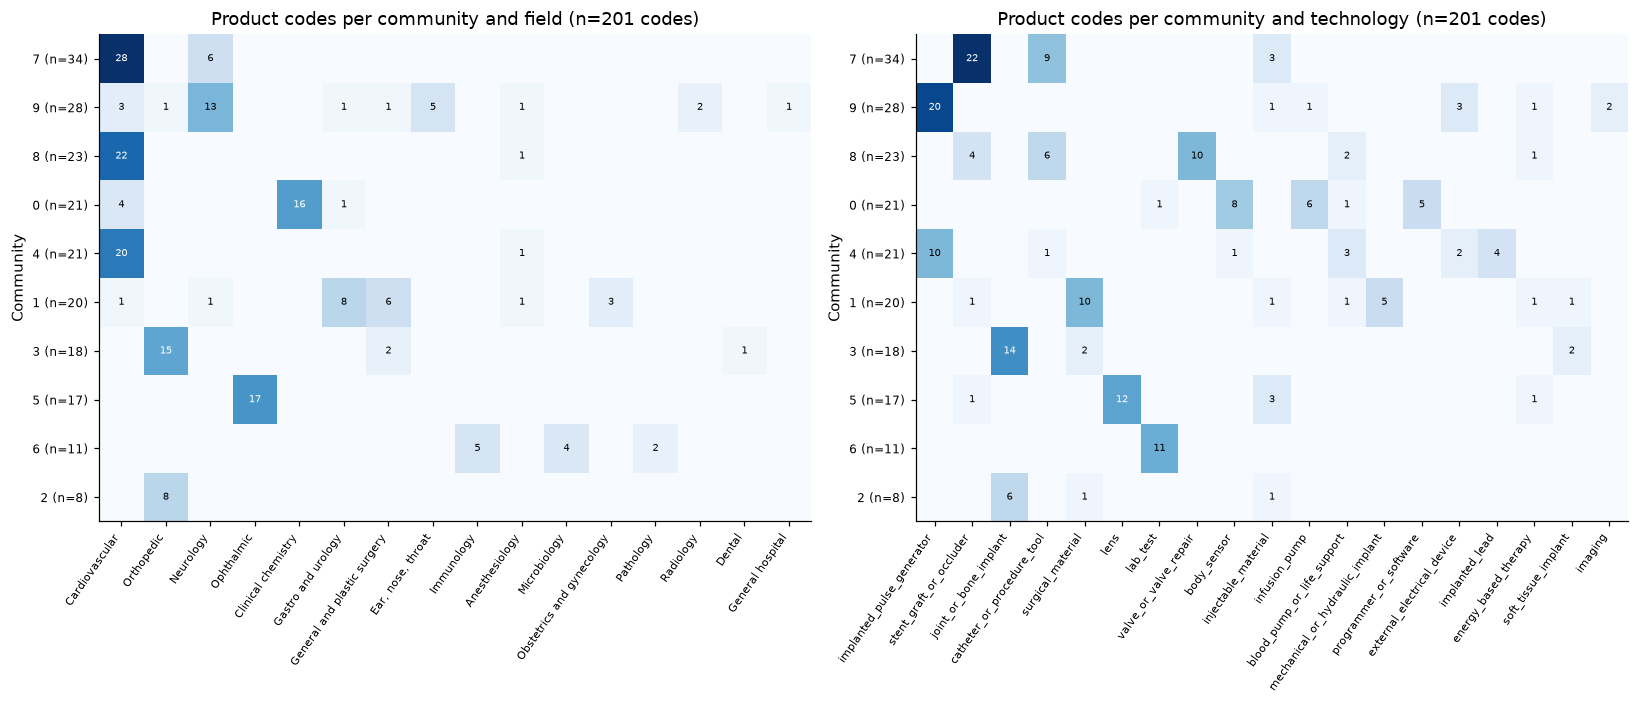

In [11]:
def heatmap(ax, table, title):
    ax.imshow(table.to_numpy(), cmap="Blues", aspect="auto")
    ax.set_xticks(range(table.shape[1]), table.columns, rotation=55, ha="right", fontsize=7)
    ax.set_yticks(range(len(table)), [f"{c} (n={n})" for c, n in table.sum(axis=1).items()], fontsize=8)
    for (r, c), v in np.ndenumerate(table.to_numpy()):
        if v:
            ax.text(c, r, v, ha="center", va="center", fontsize=6.5, color="white" if v > table.to_numpy().max() / 2 else "black")
    ax.set(title=title, ylabel="Community")


size_order = codes["community"].value_counts().index
fig, axes = plt.subplots(1, 2, figsize=(15, 0.35 * len(size_order) + 3))
for ax, label in zip(axes, LABELS):
    table = pd.crosstab(codes["community"], codes[label]).loc[size_order]
    table = table[table.sum().sort_values(ascending=False).index]
    heatmap(ax, table, f"Product codes per community and {label} (n={len(codes)} codes)")
plt.tight_layout()

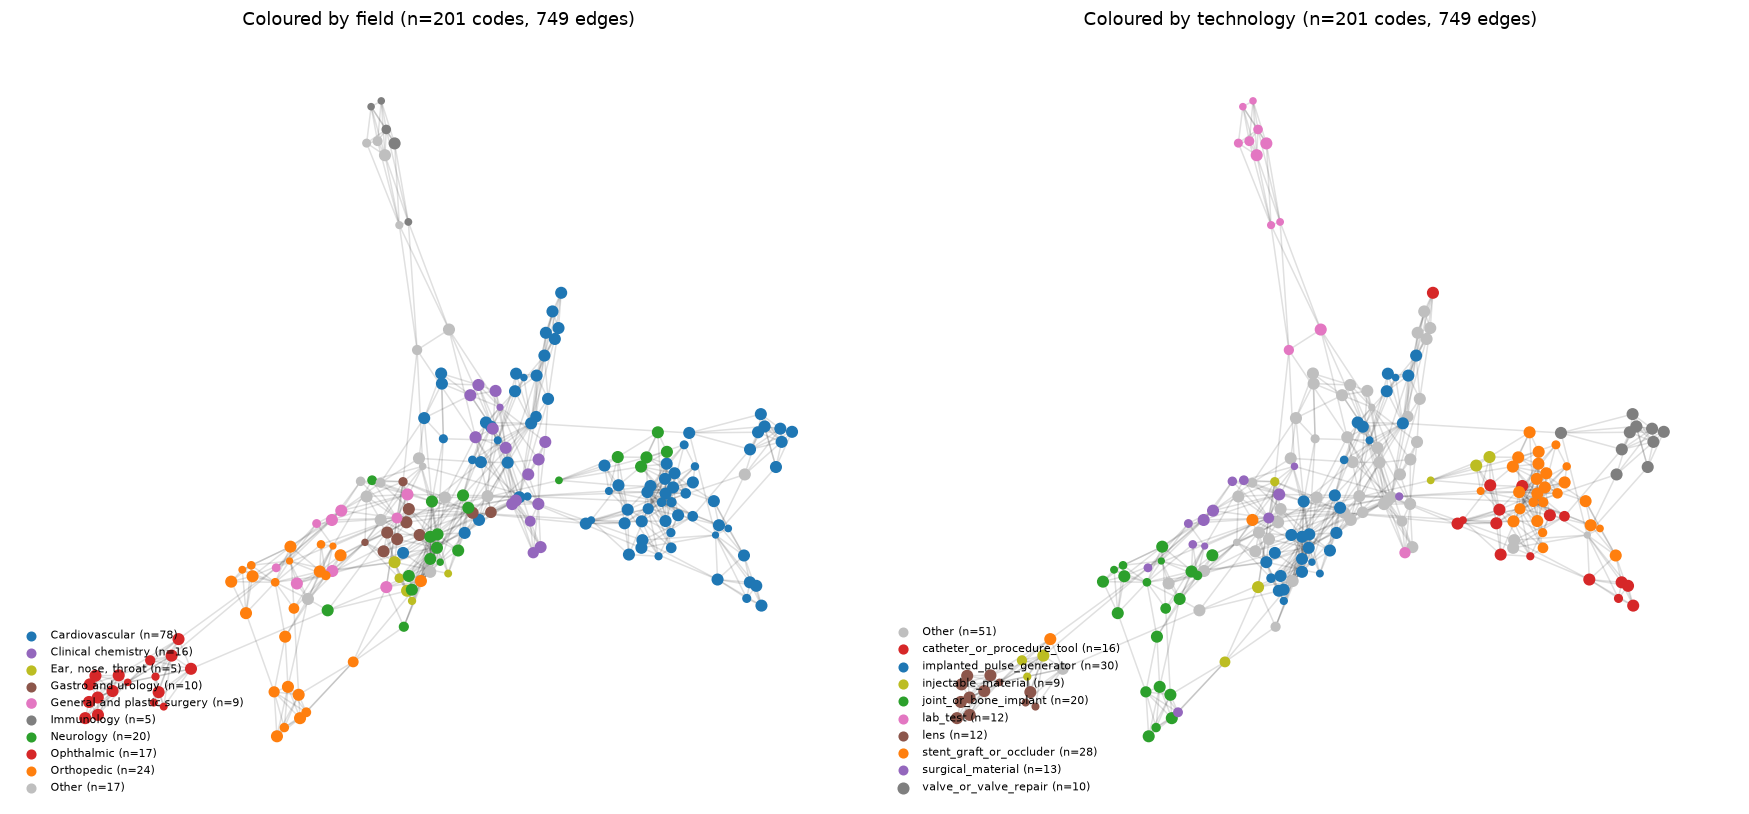

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7.5))
position = nx.spring_layout(G, weight="weight", seed=SEED)
for ax, label in zip(axes, LABELS):
    shown = codes[label].value_counts().index[:9]
    palette = dict(zip(shown, plt.cm.tab10.colors))
    nx.draw_networkx_edges(G, position, alpha=0.12, ax=ax)
    for value, group in codes.groupby(codes[label].where(codes[label].isin(shown), "Other")):
        nx.draw_networkx_nodes(
            G, position, nodelist=list(group.index), node_size=10 + group["n_reports"] / 8,
            node_color=[palette.get(value, (0.75, 0.75, 0.75))], label=f"{value} (n={len(group)})", ax=ax,
        )
    ax.legend(fontsize=7, loc="lower left", frameon=False)
    ax.set(title=f"Coloured by {label} (n={G.number_of_nodes()} codes, {G.number_of_edges()} edges)")
    ax.axis("off")
plt.tight_layout()

### What each community is about

For each community: its largest codes, the words that set its descriptions apart (TF-IDF over all communities), and the FDA problem terms most over-represented in it (lift = share in the community ÷ share overall, among terms in at least 5% of its reports).

In [13]:
sample["community"] = sample["product_code"].map(codes["community"])
community_text = sample.groupby("community")["event_description"].apply(" ".join)
tfidf = TfidfVectorizer(stop_words="english", min_df=2, max_df=0.5, token_pattern=r"(?u)\b[a-zA-Z]{3,}\b", sublinear_tf=True)
weights = tfidf.fit_transform(community_text)
vocabulary = np.array(tfidf.get_feature_names_out())


def problem_terms(frame):
    terms = (frame["product_problems"].fillna("") + "; " + frame["patient_problems"].fillna("")).str.split("; ")
    return terms.explode().str.strip().loc[lambda s: s != ""]


all_terms = problem_terms(sample).value_counts(normalize=True)

for c in size_order:
    members = codes[codes["community"] == c].sort_values("n_reports", ascending=False)
    in_community = sample[sample["community"] == c]
    counts = problem_terms(in_community).value_counts()
    share = counts / len(in_community)
    lift = (counts / counts.sum() / all_terms.reindex(counts.index)).where(share >= 0.05).dropna().nlargest(5)
    words = vocabulary[np.argsort(weights[community_text.index.get_loc(c)].toarray().ravel())[-10:][::-1]]

    print(f"=== Community {c}: {len(members)} codes, {members['field'].nunique()} fields, {members['technology'].nunique()} technologies")
    for code_, row in members.head(8).iterrows():
        print(f"   {code_}  {row['field']:<28} {row['technology']:<32} {str(row['name'])[:45]}")
    print(f"   distinctive words: {', '.join(words)}")
    print(f"   over-represented problems: {'; '.join(f'{t} (x{v:.1f})' for t, v in lift.items())}\n")

=== Community 7: 34 codes, 2 fields, 3 technologies
   NJE  Neurology                    stent_graft_or_occluder          STENT, INTRACRANIAL NEUROVASCULAR
   PJQ  Cardiovascular               injectable_material              Agent, occluding, vascular, permanent
   OUT  Neurology                    stent_graft_or_occluder          Intracranial aneurysm flow diverter
   OPR  Neurology                    stent_graft_or_occluder          Intrasaccular Flow Disruption Device
   ONU  Cardiovascular               catheter_or_procedure_tool       Drug-Eluting Peripheral Transluminal Angiopla
   PRC  Cardiovascular               catheter_or_procedure_tool       Drug-coated peripheral transluminal angioplas
   NWX  Cardiovascular               catheter_or_procedure_tool       Catheter, percutaneous transluminal coronary 
   PRL  Cardiovascular               stent_graft_or_occluder          Iliac covered stent, arterial
   distinctive words: vbx, endoprosthesis, stenosed, balloon, viabahn, micr

## 6. Check: the problem-term network

The same network is built without embeddings. Each code becomes a TF-IDF vector of the FDA problem terms on its sampled reports, and codes are linked to their 5 nearest codes.

- **Mantel test:** do the two similarity matrices agree over all pairs of codes? The null shuffles the codes of one matrix 1,000 times.
- **The same label tests** as in section 4, so the conclusions can be compared directly.

In [14]:
report_terms = problem_terms(sample)
term_docs = report_terms.groupby(sample.loc[report_terms.index, "product_code"]).agg("|".join).loc[order]
term_vectorizer = TfidfVectorizer(tokenizer=lambda s: s.split("|"), token_pattern=None, lowercase=False, sublinear_tf=True)
term_vectors = term_vectorizer.fit_transform(term_docs)
term_sim = (term_vectors @ term_vectors.T).toarray()
G_terms = knn_graph(term_sim, order, K)

a, b = text_sim[i, j], term_sim[i, j]
mantel = np.corrcoef(a, b)[0, 1]
mantel_null = []
for _ in range(N_SHUFFLES):
    p = rng.permutation(len(order))
    mantel_null.append(np.corrcoef(a, term_sim[p][:, p][i, j])[0, 1])
mantel_null = np.array(mantel_null)
print(f"Mantel correlation between text and problem-term similarity: {mantel:.2f} "
      f"(shuffled: mean {mantel_null.mean():.2f}, max {mantel_null.max():.2f}, p = {(np.sum(mantel_null >= mantel) + 1) / (N_SHUFFLES + 1):.3f})")
shared_edges = len(set(map(frozenset, G.edges)) & set(map(frozenset, G_terms.edges)))
print(f"Edges in both networks: {shared_edges} of {G.number_of_edges()} text edges")

term_partition, term_modularity, term_stability = best_partition(G_terms)
print(f"Problem-term network: {term_partition.nunique()} communities, modularity {term_modularity:.2f}, agreement between seeds {term_stability:.2f}")
print(f"Agreement between the two community splits (NMI): {normalized_mutual_info_score(codes['community'][order], term_partition[order]):.2f}")
for label in LABELS:
    print(f"Links within the same {label}: {share_within(G_terms, label):.0%}")
print()
print(nmi_table(term_partition).round(2).to_string())

term_tests = label_tests(G_terms)
term_pairs = pairs.assign(similarity=term_sim[i, j])
display(term_tests.round(3))
display(pair_table(term_pairs))
link_table(G_terms, term_pairs)

Mantel correlation between text and problem-term similarity: 0.68 (shuffled: mean -0.00, max 0.06, p = 0.001)
Edges in both networks: 376 of 749 text edges


Problem-term network: 9 communities, modularity 0.79, agreement between seeds 0.94
Agreement between the two community splits (NMI): 0.75
Links within the same field: 73%
Links within the same technology: 60%



            NMI with communities  shuffled labels
field                       0.61             0.14
technology                  0.62             0.16


,assortativity,null mean,null 99th percentile,p (one-sided)
field,0.656,-0.006,0.029,0.001
technology,0.558,-0.006,0.019,0.001
"technology, shuffled within field",0.558,0.227,0.261,0.001
"field, shuffled within technology",0.656,0.364,0.411,0.001


mean similarity  pairs
same field      same technology                             
different field different technology            0.084  15596
                same technology                 0.198    661
same field      different technology            0.160   2966
                same technology                 0.370    877

links  possible pairs  link rate  \
same field      same technology                                          
different field different technology    117           15596      0.008   
                same technology          77             661      0.116   
same field      different technology    170            2966      0.057   
                same technology         350             877      0.399   

                                      share of links  
same field      same technology                       
different field different technology           0.164  
                same technology                0.108  
same field      different technology           0.238  
                same technology                0.490

## 7. Robustness: number of neighbours

The choice of 5 neighbours is arbitrary, so the main numbers are recomputed for 3 and 10, for both networks. Fewer shuffles are used here to save time.

In [15]:
rows = []
for network, similarity in [("text", text_sim), ("problem terms", term_sim)]:
    for k in [3, 5, 10]:
        graph = knn_graph(similarity, order, k)
        result = label_tests(graph, n_shuffles=200)
        partition, _, _ = best_partition(graph, seeds=range(10))
        rows.append({
            "network": network, "k": k, "edges": graph.number_of_edges(),
            "field assortativity": result.at["field", "assortativity"],
            "technology assortativity": result.at["technology", "assortativity"],
            "p technology beyond field": result.at["technology, shuffled within field", "p (one-sided)"],
            "p field beyond technology": result.at["field, shuffled within technology", "p (one-sided)"],
            "NMI communities-field": normalized_mutual_info_score(codes["field"][order], partition[order]),
            "NMI communities-technology": normalized_mutual_info_score(codes["technology"][order], partition[order]),
        })
robustness = pd.DataFrame(rows).set_index(["network", "k"])
robustness.round(3)

edges  field assortativity  technology assortativity  \
network       k                                                          
text          3     457                0.712                     0.668   
              5     749                0.643                     0.583   
              10   1474                0.540                     0.462   
problem terms 3     434                0.751                     0.655   
              5     714                0.656                     0.558   
              10   1381                0.564                     0.442   

                  p technology beyond field  p field beyond technology  \
network       k                                                          
text          3                       0.005                      0.005   
              5                       0.005                      0.005   
              10                      0.005                      0.005   
problem terms 3                       0.005                      0.005   
              5                       0.005                      0.005   
              10                      0.005                      0.005   

                  NMI communities-field  NMI communities-technology  
network       k                                                      
text          3                   0.644                       0.674  
              5                   0.656                       0.671  
              10                  0.655                       0.633  
problem terms 3                   0.646                       0.678  
              5                   0.613                       0.623  
              10                  0.615                       0.639

## 8. Verdict by the rules set at the start

In [16]:
tech_higher = (robustness["technology assortativity"] > robustness["field assortativity"]).all()
tech_beyond = (robustness["p technology beyond field"] < 0.01).all()
field_beyond = (robustness["p field beyond technology"] < 0.01).all()
field_at_least_as_high = (robustness["field assortativity"] >= robustness["technology assortativity"]).all()

if tech_higher and tech_beyond:
    verdict = "H supported"
elif field_at_least_as_high and not (robustness["p technology beyond field"] < 0.01).any():
    verdict = "H rejected"
else:
    verdict = "H partly supported"

pd.Series({
    "technology assortativity above field's (every network and k)": tech_higher,
    "technology matters beyond field (every network and k)": tech_beyond,
    "field matters beyond technology (every network and k)": field_beyond,
    "verdict": verdict,
}, name="result").to_frame()

,result
technology assortativity above field's (every network and k),False
technology matters beyond field (every network and k),True
field matters beyond technology (every network and k),True
verdict,H partly supported


## 9. Conclusion

**By the rules set at the start, H is partly supported.** Technology and medical field both shape the network, and each still matters after the other is accounted for. Which one is "stronger" depends on how you ask.

**1. Pair by pair, technology matters about twice as much as field.**

| average text similarity | different technology | same technology |
|---|---|---|
| different field | 0.43 | **0.63** |
| same field | **0.52** | 0.72 |

Sharing a technology adds about 0.20 to the similarity of two codes, and sharing a field adds about 0.09. A spinal cord stimulator really does read more like a pacemaker than like a spinal implant. Among possible pairs, 15.6% of different-field, same-technology pairs become links, against 5.8% of same-field, different-technology pairs.

**2. In the network as a whole, field holds more links.** 71% of links share a field and 62% share a technology (assortativity 0.64 against 0.58). The reason is opportunity, not strength: there are 2,966 same-field, different-technology pairs but only 661 different-field, same-technology pairs, because most technologies are used in a single field. So the "more than field" part of H fails on the rule chosen at the start.

**3. Each label adds to the other.** Shuffling technology labels only within fields never reaches the real value (0.58 against at most 0.27). The same holds the other way round (0.64 against at most 0.41). Communities match both labels about equally (NMI 0.66 with field, 0.67 with technology).

**4. The clearest case is implanted electrical stimulation.** One community holds 28 codes from 9 fields: spinal, brain, vagus, sacral and hypoglossal nerve stimulators, cochlear and middle-ear implants, and external defibrillators. Its words (*neurostimulator, IPG, electrodes, programmer*) and problems (*failure of implant*, *inadequate pain relief*) are about the technology, not the body part.

**5. The check agrees.** The problem-term network, built with no embeddings, correlates with the text network (r = 0.68, shuffles at most 0.06) and gives the same pattern: same-technology pairs across fields are twice as likely to link as same-field pairs across technologies (11.6% against 5.7%). All of this holds for 3, 5 and 10 neighbours.

**A statement for the paper:** *Reports describe failures in terms of the technology more than the body part: two device types that share a technology are about twice as similar as two that share a medical field. Because most technologies are confined to one field, the network still looks organised by field overall. The exception that reveals the technology layer is implanted electrical stimulation, which forms a single community across nine medical fields.*

**Limits:**
- The technology labels were drafted from device names by one person (an AI assistant), after the first version of this analysis had shown that stimulators group together. The group should review `labels/technology_labels.csv` before the results are used, and a second labeller would make a good check.
- Assortativity depends on how many categories a label has and how large they are (16 fields against 19 technologies), so the pair table is the fairer comparison.
- Reports show what was reported, not what caused harm.